# Exercise 1: seeing how a neural network learns

**Why use machine learning when conventional methods already work well?**

Physics-based fitting, as in Anaklasis, uses a forward model that describes
how a structure produces reflectivity. MCMC can explore joint parameter
uncertainty with high accuracy for the chosen model, likelihood, and prior,
provided the sampling has converged adequately. These methods are already
very good, and it can be difficult to improve on their accuracy.

The practical bottleneck we address is **speed**. Conventional inference can
require many forward-model evaluations for each measurement, especially
when estimating uncertainty. Machine learning moves much of the work into
generating examples and **training**. Once trained, a network can make a new
prediction quickly: this is **inference**.

A basic neural network does not automatically enforce the physical equations.
Learning from physically simulated examples does not guarantee that every
prediction is physically consistent. Faster predictions therefore do not
automatically mean more accurate predictions. Physical checks and
conventional validation or refinement remain important.

This short notebook makes the central ideas visible using a noisy sine:

1. Combine simple hidden-unit contributions to approximate a function.
2. Adjust weights to reduce a loss.
3. See how the learning rate changes movement on a loss surface.

In the afternoon, we apply these ideas to **fast approximate reflectometry
predictions, including uncertainty estimates**, and then to joint posterior
inference with more advanced methods.

**How to use this notebook:** run in order. **Predict**, **Change**, and
**Explain** mark short interactions.

## Exercise 1.1: build a function from hidden units

We know the underlying curve, $y=\sin(3\pi x)$, and generate noisy observations.
The network receives the coordinates and noisy values, without being told to
use a sine function. The known sine is a visual reference for us.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from tqdm import tqdm

%matplotlib inline
torch.set_num_threads(2)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})

Input / target shapes: (100, 1) (100, 1)


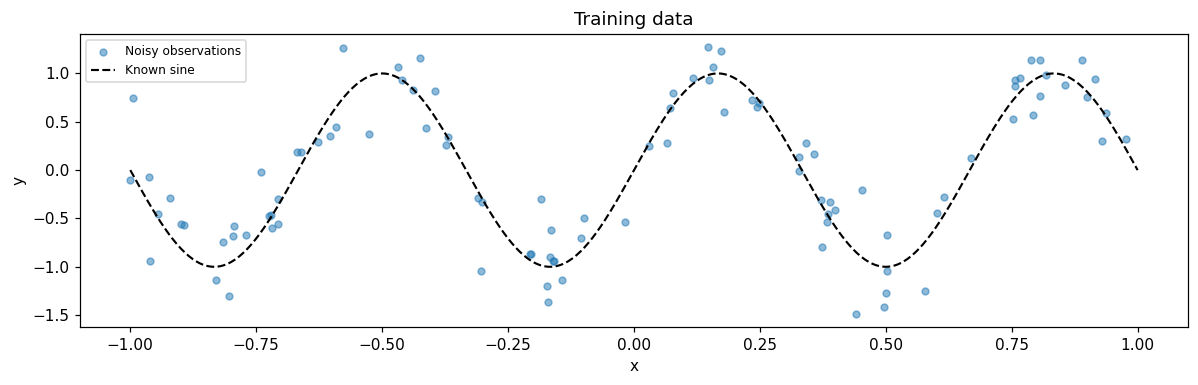

In [2]:
def sinusoid(x):
    return np.sin(3*np.pi*x[..., 0])

# Keep the data fixed when changing the model's initialization later.
data_seed = 1
np.random.seed(data_seed)
num_training_points = 100
observation_noise_variance = 0.1

x_array = np.random.uniform(-1, 1, (num_training_points, 1))
y_array = sinusoid(x_array) + np.random.normal(
    0, np.sqrt(observation_noise_variance), num_training_points
)

x = torch.tensor(x_array, dtype=torch.float32)
y = torch.tensor(y_array[:, None], dtype=torch.float32)
x_grid = torch.linspace(-1, 1, 500)[:, None]
true_curve = sinusoid(x_grid.numpy())
print("Input / target shapes:", tuple(x.shape), tuple(y.shape))

fig, axes = plt.subplots(1, 1, figsize=(11, 3.6))
axes.scatter(x_array[:, 0], y_array, s=20, alpha=0.5, label="Noisy observations")
axes.plot(x_grid[:, 0], true_curve, "k--", lw=1.4, label="Known sine")
axes.set(xlabel="x", ylabel="y", title=f"Training data")
axes.legend(fontsize=8)
fig.tight_layout()
plt.show()

### What the network computes

A hidden unit applies a sigmoid to a weighted input plus a bias:
$h_j(x)=\operatorname{sigmoid}(w_jx+b_j)$.
Its input weight and bias change the direction, steepness, and position of
the transition. The output layer combines these contributions:

$$\hat y(x)=b_{\mathrm{out}}+\sum_j v_jh_j(x).$$

The weighted contributions $v_jh_j(x)$ can rise or fall. Training adjusts
their shapes and how they combine. We will plot these contributions directly.

**Predict:** could two linear layers approximate the sine if we removed the
sigmoid between them?

**Instructor answer**

No. Without the nonlinear activation, composing two linear layers with
biases still gives one affine function, $ax+b$. The sigmoid allows the
hidden units to contribute transitions that combine into a curved function.

In [3]:
class SineModel(nn.Module):
    def __init__(self, hidden_size):
        super().__init__()
        self.fc1 = nn.Linear(1, hidden_size)
        self.fc2 = nn.Linear(hidden_size, 1)

    def forward(self, x):
        hidden = torch.sigmoid(self.fc1(x))
        return self.fc2(hidden)

def weights_init_uniform(layer):
    if isinstance(layer, nn.Linear):
        with torch.no_grad():
            layer.weight.uniform_(-0.01, 0.01)
            layer.bias.zero_()

### Train the network

The **mean squared error (MSE)** measures the discrepancy between predictions
and the observed values:

$$J=\frac{1}{N}\sum_i(\hat y_i-y_i)^2.$$

One **epoch** processes all training examples. Here it makes one weight update.
Each update follows four steps: predict, calculate loss, calculate gradients,
and update weights. A gradient tells us how the loss changes with a weight.
The learning rate controls the scale of the optimizer's adjustments.

We use **Adam**, a gradient-based optimizer with adaptive scaling. Its updates
are not identical to plain gradient descent. `zero_grad()` clears old
gradients, `backward()` calculates new ones, and `step()` changes the weights.

**Run:** start with the settings below. The model and optimizer are freshly
initialized whenever their cell is rerun; the existing training data stay fixed.

In [4]:
# Change these settings for the interactions below.
hidden_size = 5
num_epochs = 2000
learning_rate = 0.01
model_seed = 1

torch.manual_seed(model_seed)
model = SineModel(hidden_size)
model.apply(weights_init_uniform)
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
training_loss = np.empty(num_epochs)

In [5]:
for epoch in tqdm(range(num_epochs)):
    prediction = model(x)                  # 1. Predict.
    loss = criterion(prediction, y)        # 2. Calculate loss.
    optimizer.zero_grad()                  # Clear previous gradients.
    loss.backward()                        # 3. Calculate gradients.
    optimizer.step()                       # 4. Update weights.
    with torch.no_grad():
        training_loss[epoch] = criterion(model(x), y).item()

# Evaluate the final weights for every plot.
with torch.no_grad():
    prediction_grid = model(x_grid).numpy().ravel()
print(f"Final training MSE: {training_loss[-1]:.3f}")

100%|██████████████████████████████████████████████████████████████████████████████| 2000/2000 [00:02<00:00, 718.46it/s]

Final training MSE: 0.285


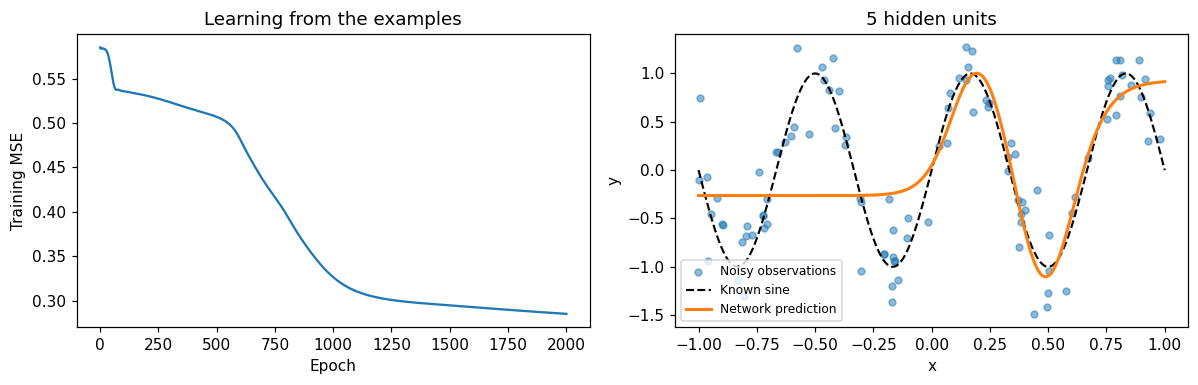

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].plot(np.arange(1, num_epochs+1), training_loss)
axes[0].set(xlabel="Epoch", ylabel="Training MSE", title="Learning from the examples")
axes[1].scatter(x_array[:, 0], y_array, s=20, alpha=0.5, label="Noisy observations")
axes[1].plot(x_grid[:, 0], true_curve, "k--", lw=1.4, label="Known sine")
axes[1].plot(x_grid[:, 0], prediction_grid, color="C1", lw=2, label="Network prediction")
axes[1].set(xlabel="x", ylabel="y", title=f"{hidden_size} hidden units")
axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()

**Explain**

1. How does training loss change, and what does it tell us about the fit?
2. Does the prediction follow every swing of the sine, or only some of them?
3. Increase `num_epochs` to 5000. Rerun the settings, training, and plotting
   cells. How do the loss and approximation change?

Keep the other settings fixed while changing one thing. The plotted loss
measures the examples used for training; independent evaluation comes in Ex2.

**Instructor answers**

1. The loss generally decreases as weights are adjusted. Plateaus and occasional
   increases can occur. A smaller training loss means better agreement with
   these observations; inspect the prediction to see which curve features
   have been learned.
2. At the reference settings, five units and 2000 updates miss some oscillations.
   The smooth prediction and known sine make this visible even when noisy
   points alone make the fit harder to judge.
3. In the checked example, 5000 updates improve the five-unit fit substantially.
   More updates give the optimizer more time to adjust the contributions;
   they do not guarantee improvement indefinitely. Return to 2000 epochs
   before comparing hidden-unit counts below.

### See the hidden-unit contributions

**Change:** use `num_epochs = 2000` and try `hidden_size = 3`, `5`, and `10`.
For each choice, rerun the **settings**, **training**, and both plotting cells.
Also try a different `model_seed`, keeping the data unchanged.

**Explain**

1. How do the rising and falling contributions below combine into the curve
   above? What role does the output bias play?
2. What changes when too few hidden units are replaced by more units?
3. Does changing initialization give identical contributions and predictions?

**Instructor answers**

1. At each coordinate, add all the weighted hidden outputs and the constant
   output bias to obtain the prediction. The transitions supply rising and
   falling parts of the approximation; they overlap rather than occupying
   strictly separate pieces of the input range.
2. Too few transitions cannot reproduce all the oscillations well. More units
   give the optimizer more contributions to arrange. At 2000 updates in the
   checked example, ten units follow the sine much better than three or five.
   Having enough rising and falling contributions is the useful picture;
   an exact unit-count threshold is not a universal rule.
3. Different initial weights can produce different learned contributions,
   optimization speeds, and fits. Similar total predictions need not use
   identical individual units. Compare with the same data and training
   duration so initialization is the changed condition.

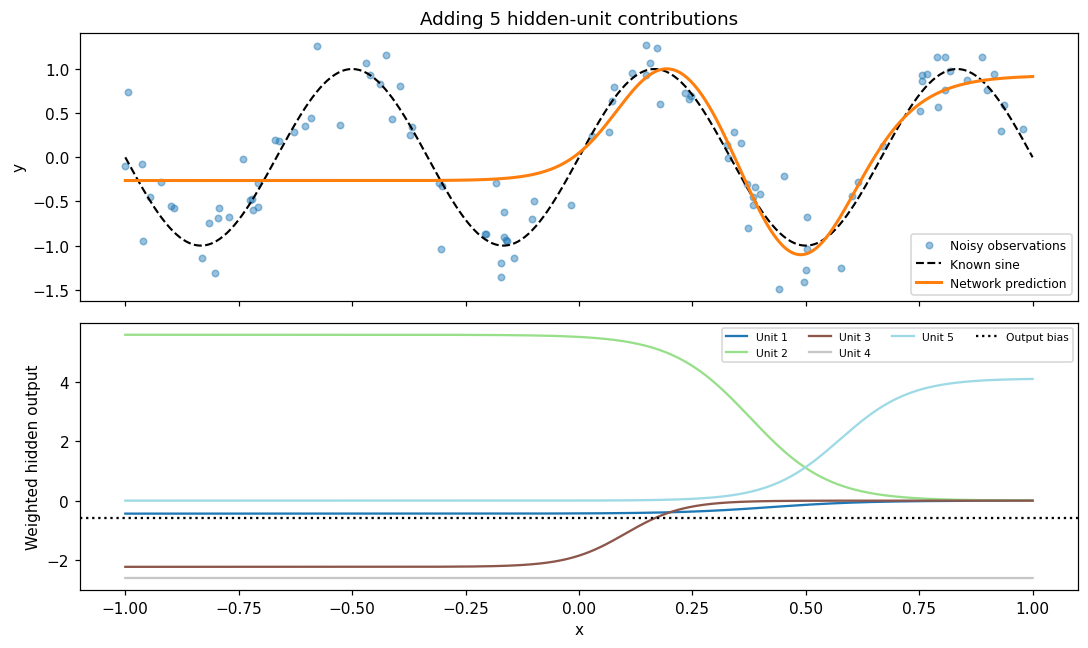

In [7]:
with torch.no_grad():
    hidden_grid = torch.sigmoid(model.fc1(x_grid))
    contributions = (hidden_grid * model.fc2.weight[0]).numpy()
    output_bias = model.fc2.bias.item()

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
axes[0].scatter(x_array[:, 0], y_array, s=18, alpha=0.45, label="Noisy observations")
axes[0].plot(x_grid[:, 0], true_curve, "k--", lw=1.4, label="Known sine")
axes[0].plot(x_grid[:, 0], prediction_grid, color="C1", lw=2, label="Network prediction")
axes[0].set(ylabel="y", title=f"Adding {hidden_size} hidden-unit contributions")
axes[0].legend(fontsize=8)
colors = plt.get_cmap("tab20")(np.linspace(0, 1, hidden_size))
for j, color in enumerate(colors):
    axes[1].plot(x_grid[:, 0], contributions[:, j], color=color, label=f"Unit {j+1}")
axes[1].axhline(output_bias, color="black", ls=":", label="Output bias")
axes[1].set(xlabel="x", ylabel="Weighted hidden output")
axes[1].legend(fontsize=7, ncol=min(4, hidden_size+1))
fig.tight_layout()
plt.show()

**Pause and discuss:** the network builds a complicated curve by combining
simple nonlinear contributions. Continue when that connection is clear.

## Exercise 1.2: watch weights move on a loss surface

We now restrict the network to two adjustable weights, $w_1$ and $w_2$,
so that we can draw the loss as a height above a two-dimensional weight plane.
Every point on the surface represents one possible setting of these weights.

We retain two sigmoid units, remove the biases, and fix the output weights
at $+1$ and $-1$. The purpose is to watch optimization move the weights.

**Predict:** what would happen to the movement if the learning rate were
extremely small? What could happen if it were excessively large?

**Instructor answer**

A very small learning rate gives tiny adjustments, so the trajectory barely
moves within the available updates. An excessively large rate can jump past
a useful region, oscillate, or enter a flat region where progress stalls.
The useful rate makes progress without such excessive jumps. This example
continues to use Adam, rather than plain steepest descent.

In [8]:
class SimpleModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(1, 2, bias=False)
        self.fc2 = nn.Linear(2, 1, bias=False)
        self.fc2.weight = nn.Parameter(torch.tensor([[1.0, -1.0]]), requires_grad=False)

    def forward(self, x):
        return self.fc2(torch.sigmoid(self.fc1(x)))

simple_model = SimpleModel()
print("Fixed output weights:", simple_model.fc2.weight)
print("Output weights require gradients:", simple_model.fc2.weight.requires_grad)
print("Adjustable weights:", sum(p.numel() for p in simple_model.parameters() if p.requires_grad))

Fixed output weights: Parameter containing:
tensor([[ 1., -1.]])
Output weights require gradients: False
Adjustable weights: 2


**Check:** are the output weights set correctly, and which weights will be learned?

**Instructor answer**

The output should show `[1., -1.]` and `requires_grad=False`. Those two output
weights are fixed; the two input-to-hidden weights in `fc1` are learned.
There are no biases in this model. Freezing parameters lets us display the
whole optimization problem using only two weight coordinates.

### Run and change the learning rate

Start with `learning_rate_gd = 0.01`. Then compare `0.00001`, `1.0` and `7.0`,
rerunning the settings, training, and plot cells for each choice. Keep
`initial_weights` fixed while comparing rates. These deliberately extreme
choices make slow movement and an excessive jump easy to see.

Finally, restore `0.01` and try a different starting pair, such as `[-1.0, 0.5]`.
The model, weights, and optimizer are reset in the settings cell each time.

In [9]:
num_epochs_gd = 2000
learning_rate_gd = 0.01
initial_weights = [-2.0, 2.0]

simple_model = SimpleModel()
with torch.no_grad():
    simple_model.fc1.weight.copy_(torch.tensor(initial_weights)[:, None])
optimizer_gd = torch.optim.Adam(simple_model.parameters(), lr=learning_rate_gd)
loss_gd = np.empty(num_epochs_gd+1)
weight_path = np.empty((num_epochs_gd+1, 2))
with torch.no_grad():
    weight_path[0] = simple_model.fc1.weight[:, 0].numpy()
    loss_gd[0] = criterion(simple_model(x), y).item()

In [10]:
for epoch in tqdm(range(num_epochs_gd)):
    prediction = simple_model(x)
    loss = criterion(prediction, y)
    optimizer_gd.zero_grad()
    loss.backward()
    optimizer_gd.step()

    # Record weights and loss at the same, updated state.
    with torch.no_grad():
        weight_path[epoch+1] = simple_model.fc1.weight[:, 0].numpy()
        loss_gd[epoch+1] = criterion(simple_model(x), y).item()
print(f"Initial / final training MSE: {loss_gd[0]:.3f} / {loss_gd[-1]:.3f}")

100%|█████████████████████████████████████████████████████████████████████████████| 2000/2000 [00:00<00:00, 2695.12it/s]

Initial / final training MSE: 1.038 / 0.536


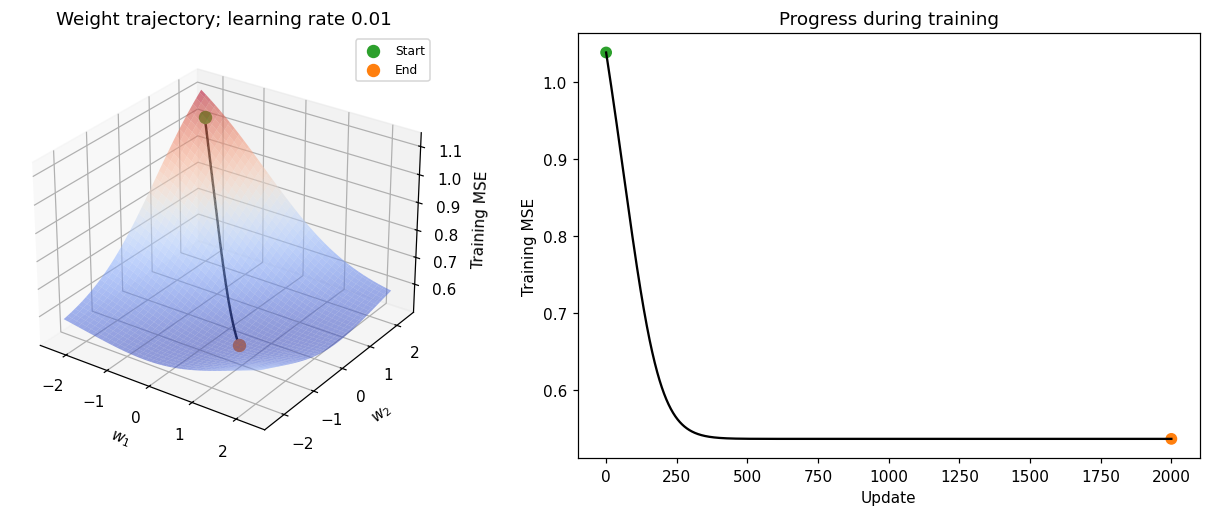

In [11]:
# Show a weight range containing the complete trajectory.
limit = max(2.0, np.abs(weight_path).max()) * 1.15
axis_weights = np.linspace(-limit, limit, 80)
w1_grid, w2_grid = np.meshgrid(axis_weights, axis_weights)
loss_surface = np.empty_like(w1_grid)
surface_model = SimpleModel()
with torch.no_grad():
    for i in range(len(axis_weights)):
        for j in range(len(axis_weights)):
            surface_model.fc1.weight[:, 0].copy_(
                torch.tensor([w1_grid[i, j], w2_grid[i, j]], dtype=torch.float32)
            )
            loss_surface[i, j] = criterion(surface_model(x), y).item()

fig = plt.figure(figsize=(12, 4.8))
ax = fig.add_subplot(1, 2, 1, projection="3d")
ax.plot_surface(w1_grid, w2_grid, loss_surface, cmap="coolwarm", alpha=0.55,
                linewidth=0, antialiased=True, rstride=2, cstride=2)
ax.plot(weight_path[:, 0], weight_path[:, 1], loss_gd, color="black", lw=1.6)
ax.scatter(*weight_path[0], loss_gd[0], color="C2", s=60, label="Start", depthshade=False)
ax.scatter(*weight_path[-1], loss_gd[-1], color="C1", s=60, label="End", depthshade=False)
ax.set(xlabel=r"$w_1$", ylabel=r"$w_2$", zlabel="Training MSE",
       title=f"Weight trajectory; learning rate {learning_rate_gd:g}")
ax.view_init(elev=28, azim=-55)
ax.legend(fontsize=8)
progress_ax = fig.add_subplot(1, 2, 2)
progress_ax.plot(np.arange(num_epochs_gd+1), loss_gd, color="black")
progress_ax.scatter([0, num_epochs_gd], [loss_gd[0], loss_gd[-1]], color=["C2", "C1"], s=45)
progress_ax.set(xlabel="Update", ylabel="Training MSE", title="Progress during training")
fig.tight_layout()
plt.show()

**Explain**

1. How does the learning rate change movement on the surface and the loss curve?
2. Why can both a very small and a very large rate give poor progress?
3. How does changing the starting pair change the trajectory?

**Instructor answers**

1. At `0.01`, the reference trajectory moves toward lower loss. At `0.00001`,
   it barely leaves the starting point within 2000 updates. At `1.0` and  `7.0` weight updates start to oscillate. At `100.0`, it
   jumps far away and ends with a poor loss. The surface is redrawn to include
   the entire path, so compare the axis scales as well as the path lengths.
2. A tiny rate makes each change too small to get far in the allotted time.
   An excessively large rate can overshoot useful regions and drive the
   sigmoids into saturation, where their gradients become very small.
   The learning rate changes speed, stability, and which region is reached.
3. The starting weights choose the initial position and local gradients.
   Another start can produce another path and possibly another final fit.
   With the symmetric starting pair, the default path stays approximately
   on a symmetry line; an asymmetric pair makes more of the two-dimensional
   movement visible. Adam uses gradient history and adaptive scaling, so
   its path need not follow the direction of plain steepest descent.

## From this picture to reflectometry

A network combines learned contributions to make a prediction. Training adjusts
its weights to reduce a chosen loss, and the learning rate affects how those
adjustments proceed. These are the same operations we use in Ex2.

There, the input becomes a reflectivity curve and the target becomes layer SLD.
We then examine predictions on new examples and extend the output to describe
uncertainty. The afternoon PANPE session continues to fast approximate joint
posterior inference, with physical validation and conventional refinement
remaining important.
